### Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

### Load data

In [2]:
data = pd.read_csv("faithful.csv").drop(columns="Unnamed: 0",axis=1)
data.head()

,eruptions,waiting
0,3.600,79
1,1.800,54
2,3.333,74
3,2.283,62
4,4.533,85


#### a) Treat each data entry as a 2 dimensional feature vector. Parse and plot all data points on 2-D plane.

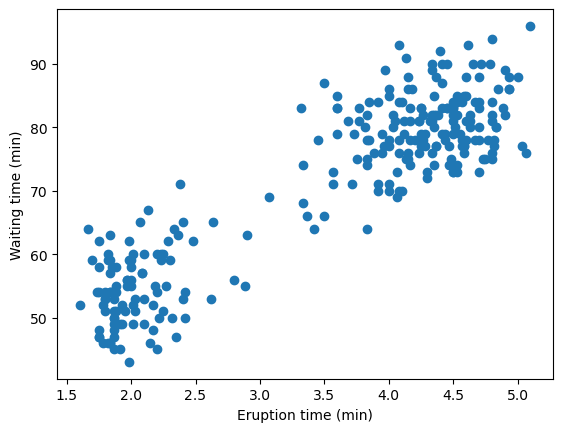

In [3]:
X = data.to_numpy()

plt.figure()
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel("Eruption time (min)")
plt.ylabel("Waiting time (min)")
plt.show()

#### b) Write the expression for $P\theta_t (z = k | x)$, which is the posterior of each data point $x^{i}$

$P\theta_t (z = k | x) = \frac{P\theta_t (z = k, x)}{P\theta_t(x)} = \frac{P\theta_t (z = k, x)}{\sum^{K}_{l=1}P\theta_t(x | z=l) P\theta_t(z=l)}$


#### c) Write down the formula for $\mu_k$ , Σk , and for the parameters φ at the M-step

- $\mu_k = \frac{\sum^{n}_{i=1}P(z=k | x^{(i)})x^{(i)}}{n_k}$
- $\sum_k = \frac{ \sum_{i=1}^{n} P(z=k | x^{(i)}) (x^{(i)} - \mu_k)(x^{(i)} - \mu_k)^{T} }{n_k}$
- $n_k = \sum_{i=1}^{n}P(z=k | x^{(i)}) $

#### d) implement and run EM algorithm

#### i) implement EM algorithm

In [4]:
d = 2 # number of features
K = 2 # number of clusters
n = X.shape[0] # dataset size

# parameters
mus = np.zeros([K,d])
Sigmas = np.zeros([K,d,d])
phis = np.zeros([K])

In [18]:
def multivariate_gaussian(x, mu, Sigma):
    d = x.shape[0]
    det = np.linalg.det(Sigma)
    inv = np.linalg.inv(Sigma)
    norm = (2 * np.pi) ** (d / 2) * np.sqrt(det)
    diff = x - mu
    return np.exp(-0.5 * diff.T @ inv @ diff) / norm

def exp_max(X, mus, Sigmas, phis, max_iters=100, tol=1e-3):
    """Run EM for a Gaussian mixture model.
    X: (n, d) data
    mus: (K, d) initial means
    Sigmas: (K, d, d) initial covariances
    phis: (K,) initial mixing weights
    Returns: (mus, Sigmas, phis, history)
    history contains lists of mus over iterations for plotting
    """
    n, d = X.shape
    K = mus.shape[0]
    post = np.zeros((n, K))

    history = {
        'mus': [mus.copy()],
        'phis': [phis.copy()]
    }

    for it in range(max_iters):
        # E-step r_{ik} = p(z=k|x_i)
        for i in range(n):
            x = X[i]
            numerators = np.zeros(K)
            for k in range(K):
                Sigma_k = Sigmas[k]
                numerators[k] = phis[k] * multivariate_gaussian(x, mus[k], Sigma_k)
            denom = numerators.sum()
            if denom == 0:
                # avoid divide by zero: uniform prob
                post[i] = np.ones(K) / K
            else:
                post[i] = numerators / denom

        # M-step: update parameters using prior prob
        N_k = post.sum(axis=0)  # shape (K,)

        new_mus = np.zeros_like(mus)
        new_Sigmas = np.zeros_like(Sigmas)
        new_phis = N_k / n

        for k in range(K):
            if N_k[k] == 0:
                # reinitialize this component randomly from data
                new_mus[k] = X[np.random.choice(n)]
                new_Sigmas[k] = np.cov(X.T)
                continue
            # mean
            weighted_sum = (post[:, k][:, None] * X).sum(axis=0)
            new_mus[k] = weighted_sum / N_k[k]
            # covariance
            diff = X - new_mus[k]
            S = np.zeros((d, d))
            for i in range(n):
                S += post[i, k] * np.outer(diff[i], diff[i])
            new_Sigmas[k] = S / N_k[k]

        # check convergence on means and phis
        delta = np.linalg.norm(new_mus - mus) + np.linalg.norm(new_phis - phis)
        mus = new_mus
        Sigmas = new_Sigmas
        phis = new_phis

        history['mus'].append(mus.copy())
        history['phis'].append(phis.copy())

        if delta < tol:
            break

    return mus, Sigmas, phis, history

#### ii) termination criterion
- I used log-likelihood as my termination criterion for the EM algorithm because it measures  the relative improvement in model fit in an intuitive and robust way. More specifically, the threshold for termination using log-likelihood is 1e-3, which I found to be a standard threshold when researching commonly used thresholds for this value (based on an established statistics textbook, StatLect).

#### iii) plot trajectories of two mean vectors

Final means: [[ 4.28966211 79.96811683]
 [ 2.03638861 54.47851793]]
Final phis: [0.64412708 0.35587292]


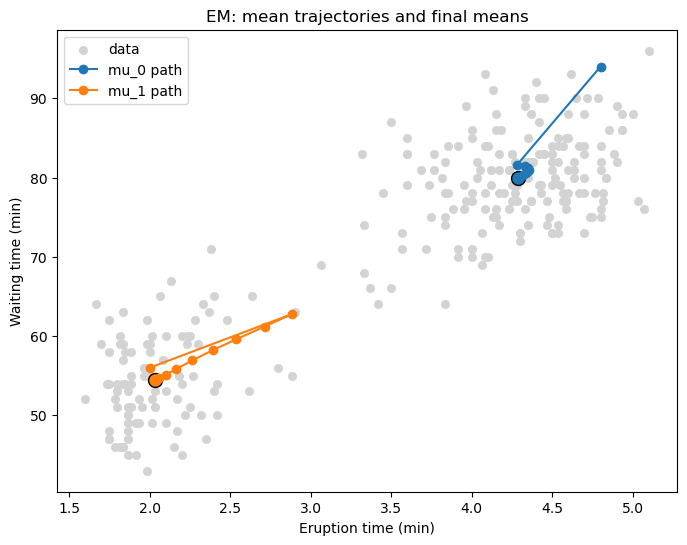

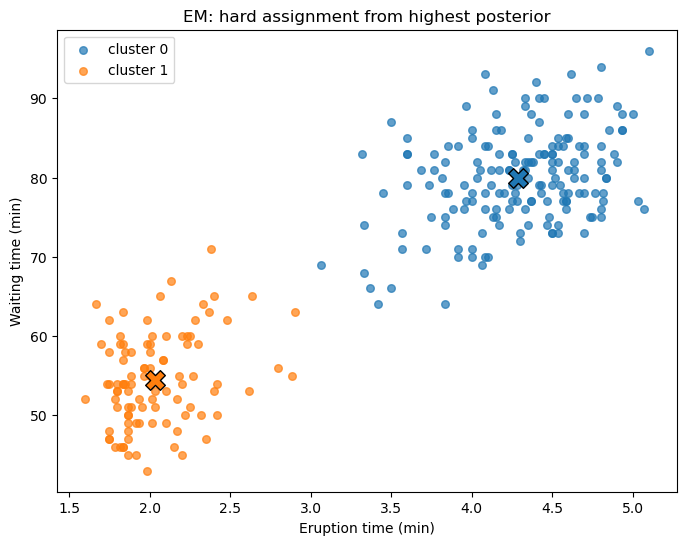

In [19]:
# initialize parameters
np.random.seed(0)
K = 2
d = X.shape[1]
# init mus: pick K random points
init_idx = np.random.choice(X.shape[0], K, replace=False)
init_mus = X[init_idx].astype(float)
# init covariances: overall covariance
init_Sigmas = np.array([np.cov(X.T) for _ in range(K)])
# init phis uniformly
init_phis = np.ones(K) / K

# run EM
mus_f, Sigmas_f, phis_f, history = exp_max(X, init_mus.copy(), init_Sigmas.copy(), init_phis.copy(), max_iters=200, tol=1e-5)
print('Final means:', mus_f)
print('Final phis:', phis_f)

# Plot data and mean trajectories
mus_hist = np.array(history['mus'])  # shape (iters+1, K, d)
plt.figure(figsize=(8,6))
plt.scatter(X[:,0], X[:,1], c='lightgray', s=30, label='data')
colors = ['C0','C1']
for k in range(K):
    traj = mus_hist[:, k, :]
    plt.plot(traj[:,0], traj[:,1], '-o', color=colors[k], label=f'mu_{k} path')
    plt.scatter(traj[-1,0], traj[-1,1], color=colors[k], edgecolor='k', s=100)
plt.xlabel('Eruption time (min)')
plt.ylabel('Waiting time (min)')
plt.legend()
plt.title('EM: mean trajectories and final means')
plt.show()

# Show soft cluster assignment (color by highest responsibility)
# recompute responsibilities for final params
n = X.shape[0]
resp = np.zeros((n, K))
for i in range(n):
    x = X[i]
    nums = np.zeros(K)
    for k in range(K):
        nums[k] = phis_f[k] * multivariate_gaussian(x, mus_f[k], Sigmas_f[k])
    denom = nums.sum()
    if denom == 0:
        resp[i] = np.ones(K) / K
    else:
        resp[i] = nums / denom
assign = resp.argmax(axis=1)
plt.figure(figsize=(8,6))
for k in range(K):
    plt.scatter(X[assign==k,0], X[assign==k,1], s=30, label=f'cluster {k}', alpha=0.7)
    plt.scatter(mus_f[k,0], mus_f[k,1], color=colors[k], edgecolor='k', s=200, marker='X')
plt.xlabel('Eruption time (min)')
plt.ylabel('Waiting time (min)')
plt.legend()
plt.title('EM: hard assignment from highest posterior')
plt.show()

#### e) If you were to run K-means clustering instead of the EM algorithm you just implemented, do you think you will get different clusters? Comment on why do you think the results will or will not change.
- As long as the hyperparameters for K-Means are chosen well (e.g. initialization method), it's unlikely that the clusters will be meaningfully different because the data are very clearly separable. However, because K-Means has a different underlying optimization method, it's possible that some of the data points that lie on the border between clusters might differ in assignment. 
- After running K-Means, I found that its cluster assignments match with GMM EM model approximately 98% of the time, with only a few differences around the cluster border. 

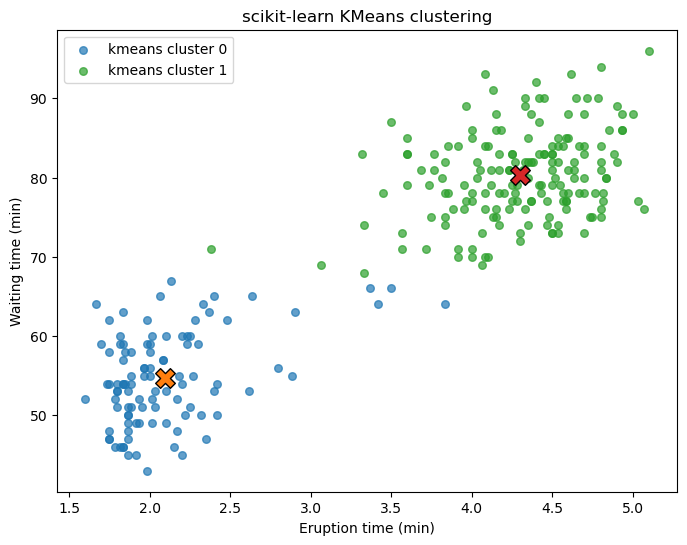

Agreement between EM (hard) and scikit-learn KMeans: 98.16%


In [21]:
# K-means using scikit-learn for comparison
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
labels_sk = kmeans.fit_predict(X)
centers_sk = kmeans.cluster_centers_

plt.figure(figsize=(8,6))
colors = ['C2', 'C3']
for k in range(2):
    plt.scatter(X[labels_sk==k,0], X[labels_sk==k,1], s=30, alpha=0.7, label=f'kmeans cluster {k}')
    plt.scatter(centers_sk[k,0], centers_sk[k,1], marker='X', s=200, edgecolor='k')
plt.title('scikit-learn KMeans clustering')
plt.xlabel('Eruption time (min)')
plt.ylabel('Waiting time (min)')
plt.legend()
plt.show()

# Compute agreement between EM (hard assignment from 'assign') and KMeans labels
# For K=2 a simple label-flip check suffices
agree_direct = np.mean(assign == labels_sk)
agree_flipped = np.mean(assign == (1 - labels_sk))
agree = max(agree_direct, agree_flipped)
print(f'Agreement between EM (hard) and scikit-learn KMeans: {agree*100:.2f}%')